## Advanced models

In [59]:
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [60]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2015-2016
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2016-2017
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2017-2018
Data is available on your system. Will be loaded from: C:\Users\GM\Desktop\IFT-6758\data\regular_season\2018-2019


In [61]:
df = engineered_data_frame(data)

C:\Users\GM\Desktop\IFT-6758\notebooks\util\engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [62]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020001,R,7,6,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,11,55.0,-94.0,154.275727,34.525353,False,10.007980,0.00000,10.007980,14.025066
1,2015020001,R,9,8,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Giveaway,Snap Shot,...,7,79.0,37.0,50.477718,10.000000,False,0.000000,0.00000,0.000000,7.211103
2,2015020001,R,10,9,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Shot,Snap Shot,...,1,75.0,79.0,4.123106,14.035669,True,-4.085617,0.00000,-4.085617,4.123106
3,2015020001,R,13,12,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Hit,Wrist Shot,...,18,55.0,91.0,79.605276,49.517674,False,-46.636577,0.00000,-46.636577,4.422515
4,2015020001,R,21,20,Toronto Maple Leafs,right,Montréal Canadiens,Shot,Faceoff,Tip-In,...,5,61.0,69.0,22.472205,28.017851,False,-2.045408,0.00000,-2.045408,4.494441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021271,R,276,275,San Jose Sharks,left,Colorado Avalanche,Shot,Giveaway,Slap Shot,...,33,67.0,29.0,66.030296,29.068884,False,-40.815084,0.00000,-40.815084,2.000918
311102,2018021271,R,281,280,San Jose Sharks,left,Colorado Avalanche,Shot,Faceoff,Wrist Shot,...,29,78.0,69.0,24.698178,11.045361,False,5.194429,0.00000,5.194429,0.851661
311103,2018021271,R,291,290,San Jose Sharks,left,Colorado Avalanche,Shot,Missed Shot,Wrist Shot,...,19,82.0,71.0,12.529964,12.206556,False,55.007980,0.00000,55.007980,0.659472
311104,2018021271,R,292,291,San Jose Sharks,left,Colorado Avalanche,Shot,Shot,Wrist Shot,...,1,81.0,82.0,9.055385,8.062258,True,7.125016,55.00798,-47.882963,9.055385


In [63]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [64]:
features_columns = ['Period_Time_Seconds', 'Period', 'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                    'Shoot_Type', 'Last_Event_Type', 'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Rebond', 'Delta_Angle', 'Speed',
                    'Powerplay_Since', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
df_features = df[features_columns]
df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df = df_features
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   311106 non-null  int64  
 1   Period                311106 non-null  int64  
 2   X_Coordinate          311088 non-null  float64
 3   Y_Coordinate          311088 non-null  float64
 4   Distance_Net          311086 non-null  float64
 5   Angle                 311085 non-null  float64
 6   Shoot_Type            311068 non-null  object 
 7   Last_Event_Type       311106 non-null  object 
 8   Last_Coordinate_X     306148 non-null  float64
 9   Last_Coordinate_Y     306149 non-null  float64
 10  Time_Between_Events   311106 non-null  int64  
 11  Distance_Last_Event   306133 non-null  float64
 12  Rebond                311106 non-null  bool   
 13  Delta_Angle           311081 non-null  float64
 14  Speed                 306112 non-null  float64
 15  

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\3377483367.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


In [65]:
df = df.dropna()

In [66]:
df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\3740469922.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)


In [67]:
df = df[df.Speed!=np.inf]

In [68]:
df.is_goal.value_counts()

0    273317
1     27173
Name: is_goal, dtype: int64

In [69]:
df

,Period_Time_Seconds,Period,X_Coordinate,Y_Coordinate,Distance_Net,Angle,Shoot_Type,Last_Event_Type,Last_Coordinate_X,Last_Coordinate_Y,Time_Between_Events,Distance_Last_Event,Rebond,Delta_Angle,Speed,Powerplay_Since,Friendly_Non_Goalies,Opponent_Non_Goalies,is_goal
0,51,1,-55.0,6.0,34.525353,10.007980,Wrist Shot,Hit,94.0,-34.0,11,154.275727,0,10.007980,14.025066,0,5,5,0
1,65,1,-79.0,0.0,10.000000,0.000000,Snap Shot,Giveaway,-37.0,-28.0,7,50.477718,0,0.000000,7.211103,0,5,5,0
2,66,1,-75.0,-1.0,14.035669,-4.085617,Snap Shot,Shot,-79.0,0.0,1,4.123106,1,-4.085617,4.123106,0,5,5,0
3,113,1,-55.0,-36.0,49.517674,-46.636577,Wrist Shot,Hit,-91.0,35.0,18,79.605276,0,-46.636577,4.422515,0,5,5,0
4,157,1,-61.0,-1.0,28.017851,-2.045408,Tip-In,Faceoff,-69.0,-22.0,5,22.472205,0,-2.045408,4.494441,0,5,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,937,3,67.0,-19.0,29.068884,-40.815084,Slap Shot,Giveaway,29.0,35.0,33,66.030296,0,-40.815084,2.000918,0,5,5,0
311102,993,3,-78.0,1.0,11.045361,5.194429,Wrist Shot,Faceoff,-69.0,-22.0,29,24.698178,0,5.194429,0.851661,0,5,5,0
311103,1119,3,-82.0,10.0,12.206556,55.007980,Wrist Shot,Missed Shot,-71.0,4.0,19,12.529964,0,55.007980,0.659472,0,5,5,0
311104,1120,3,-81.0,1.0,8.062258,7.125016,Wrist Shot,Shot,-82.0,10.0,1,9.055385,1,-47.882963,9.055385,0,5,5,0


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 300490 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   300490 non-null  int64  
 1   Period                300490 non-null  int64  
 2   X_Coordinate          300490 non-null  float64
 3   Y_Coordinate          300490 non-null  float64
 4   Distance_Net          300490 non-null  float64
 5   Angle                 300490 non-null  float64
 6   Shoot_Type            300490 non-null  object 
 7   Last_Event_Type       300490 non-null  object 
 8   Last_Coordinate_X     300490 non-null  float64
 9   Last_Coordinate_Y     300490 non-null  float64
 10  Time_Between_Events   300490 non-null  int64  
 11  Distance_Last_Event   300490 non-null  float64
 12  Rebond                300490 non-null  int64  
 13  Delta_Angle           300490 non-null  float64
 14  Speed                 300490 non-null  float64
 15  

In [71]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,:-1], df.iloc[:,-1], test_size = 0.20, random_state=42)

In [72]:
features_to_standardize = ['Period_Time_Seconds',  'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                     'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Delta_Angle', 'Speed',
                    'Powerplay_Since']
features_one_hot = ['Shoot_Type', 'Last_Event_Type']
features_to_keep = ['Period', 'Rebond', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
my_transformer = ColumnTransformer([('standard', StandardScaler(), features_to_standardize),
                                    ('one-hot', OneHotEncoder(), features_one_hot)],
                                   remainder='passthrough')
X_train = my_transformer.fit_transform(X_train)
X_test = my_transformer.transform(X_test)
y_test.reset_index(inplace= True, drop=True)
y_train.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Last_Coordinate_X',
       'standard__Last_Coordinate_Y', 'standard__Time_Between_Events',
       'standard__Distance_Last_Event', 'standard__Delta_Angle',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Blocked Shot',
       'one-hot__Last_Event_Type_Faceoff',
       'one-hot__Last_Event_Type_Giveaway',
       'one-hot__Last_Event_Type_Goal', 'one-hot__Last_Event_Type_Hit',
       'one-hot__Last_Event_Type_Missed Shot',
       'one-hot__Last_Event_Type_Penalty',
       'one-hot__Last_Event_Type_Shot',
       'one-hot__Last_Event_Type

## Model on distance and angle

In [73]:
X_train_angle_and_distance = X_train[:,3:5]
X_test_angle_and_distance = X_test[:,3:5]
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier(tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train_angle_and_distance, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train_angle_and_distance,y_train),2))
result_xgb = model_xgb.score(X_test_angle_and_distance,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.9


f1 score: 0.005457522284882665


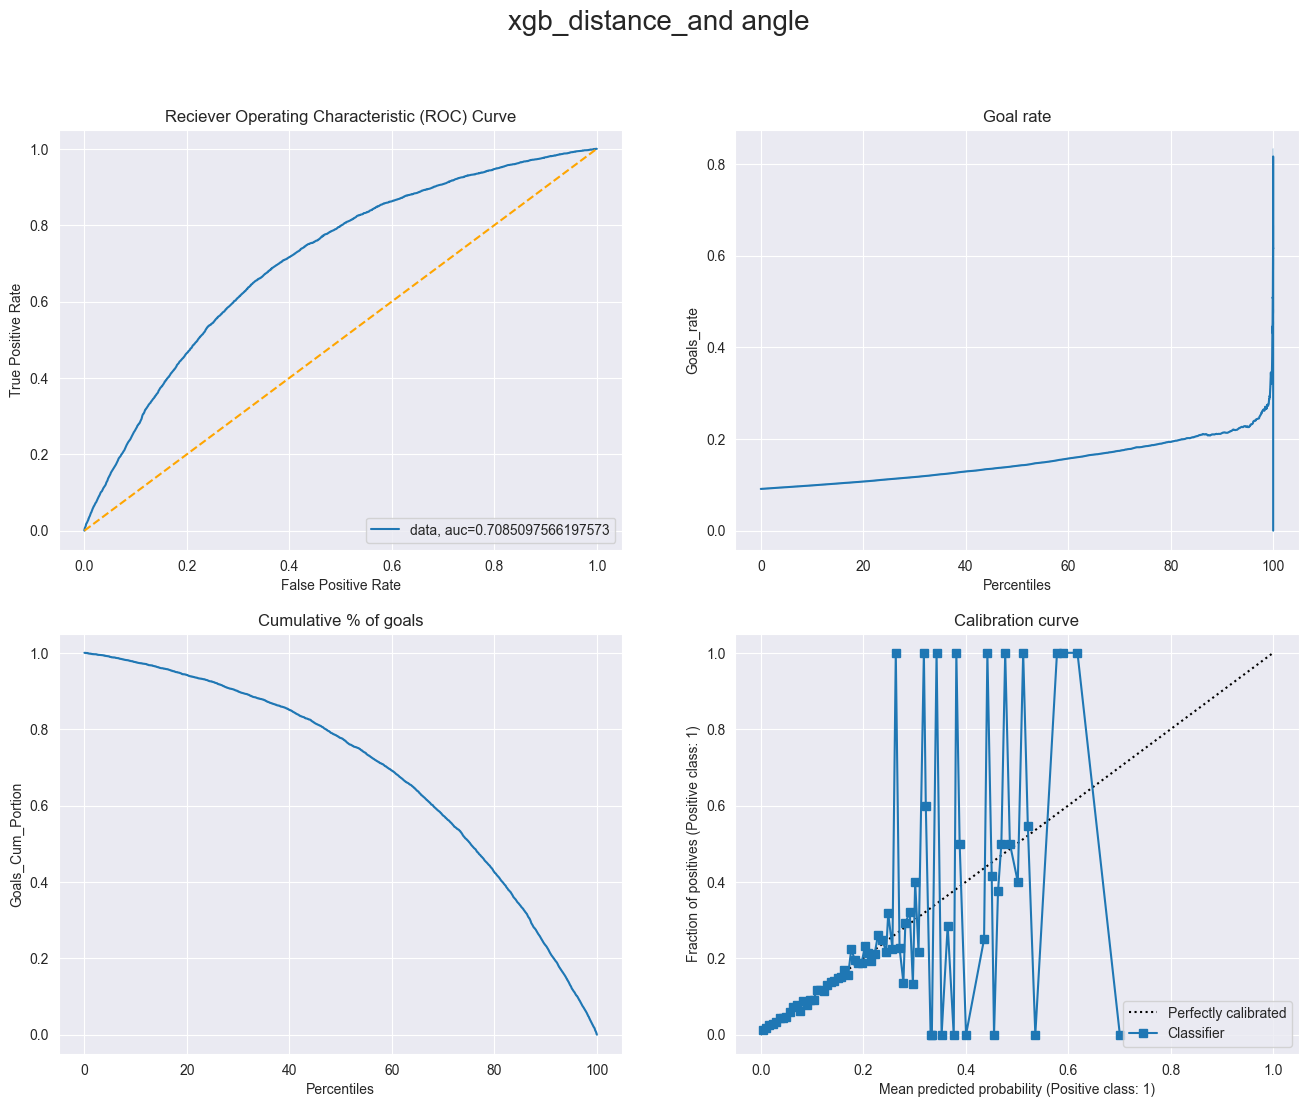

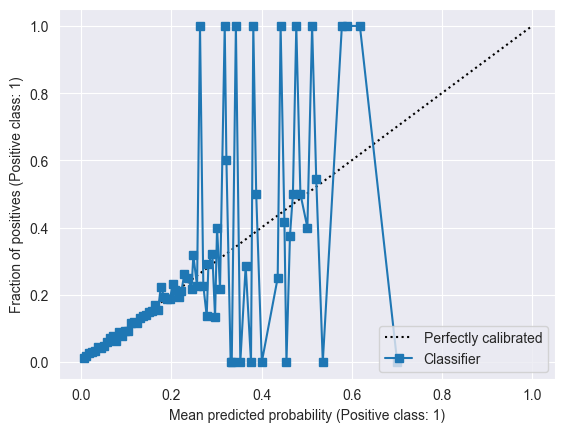

In [75]:
fig = generate_four_curves("xgb_distance_and angle", y_test, classi.predict_proba(X_test_angle_and_distance)[:,1], 150)
f1 = metrics.f1_score(y_test, classi.predict(X_test_angle_and_distance))
print(f"f1 score: {f1}")

In [76]:
max(classi.predict_proba(X_test_angle_and_distance)[:,1])

0.7007626

### Model on all features + Hyperparameter tuning

In [77]:
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier(tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.98


f1 score: 0.059996531992370386


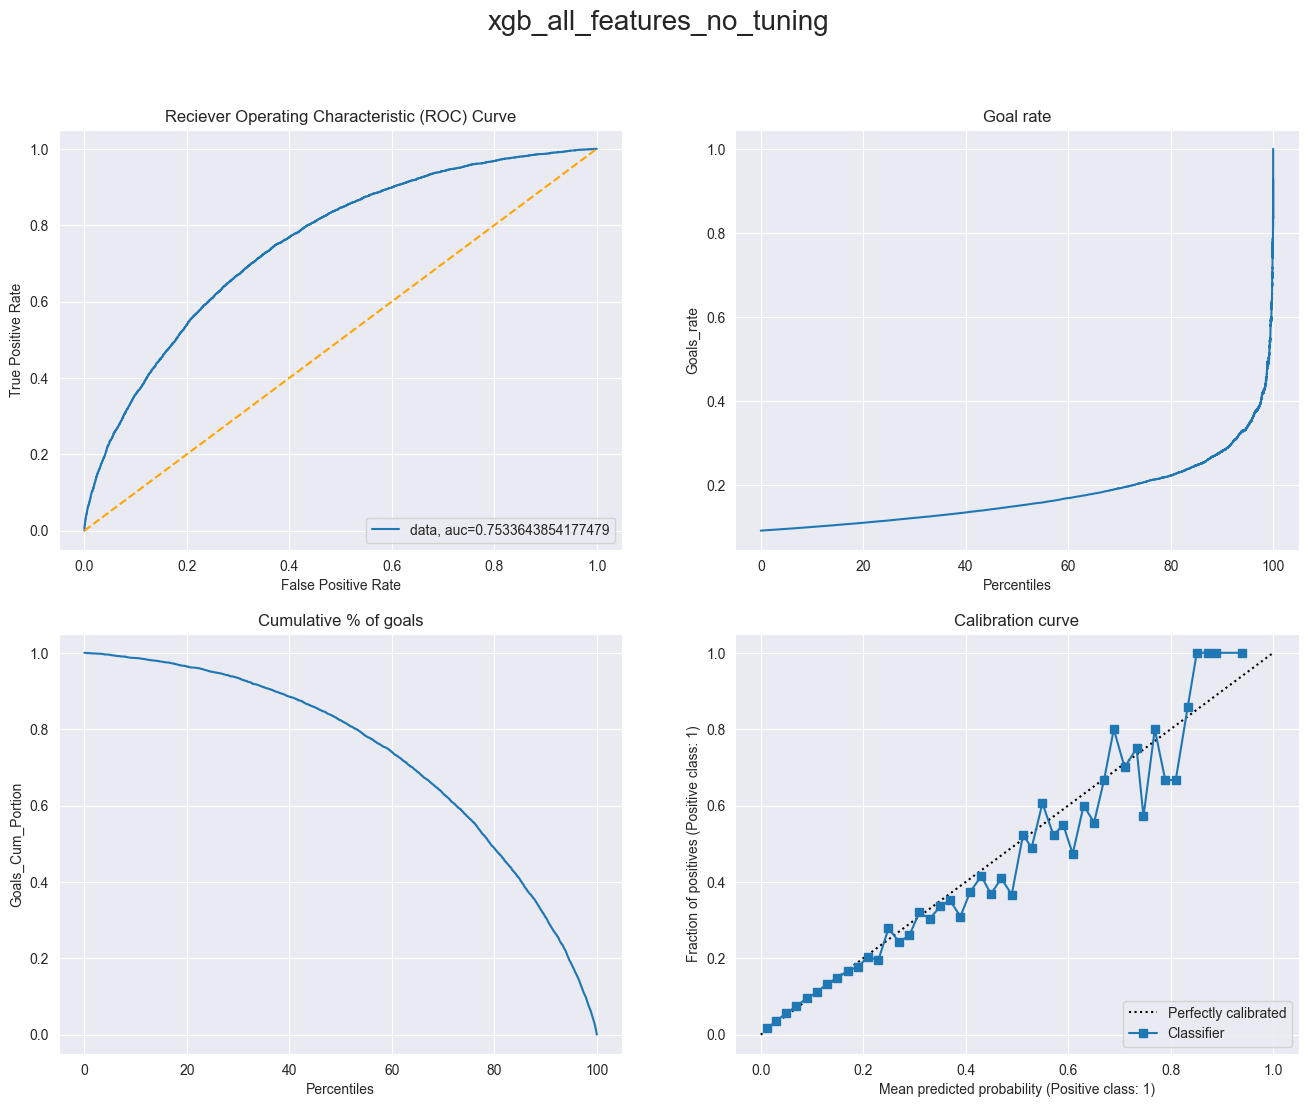

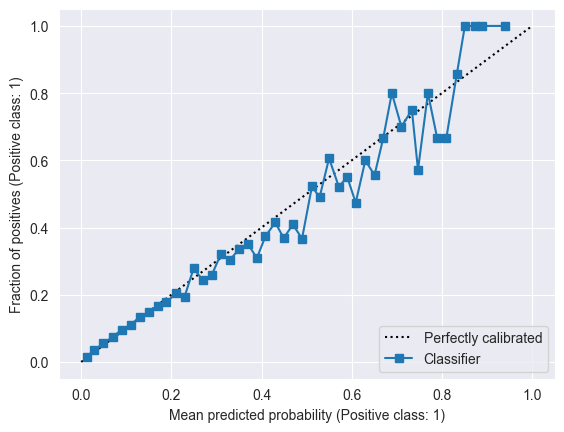

In [78]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, classi.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, classi.predict(X_test))
print(f"f1 score: {f1}")

In [79]:
max(classi.predict_proba(X_test)[:,1])

0.9393196

We start tuning our hyperparams

In [80]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),
     'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='f1', cv=5,  #plus iterations, plus chances trouver la bonne combinaison
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [81]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'scale_pos_weight': 1.0, 'max_depth': 0, 'max_delta_step': 10.0, 'gamma': 0.04081632653061224}
0.08472618101416951


In [82]:
model = grid_search.best_estimator_
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0.04081632653061224,
              gpu_id=0, grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=10.0, max_depth=0, max_leaves=0,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=0, num_parallel_tree=1, predictor='auto',
              random_state=0, ...)

f1 score: 0.09206913261185593


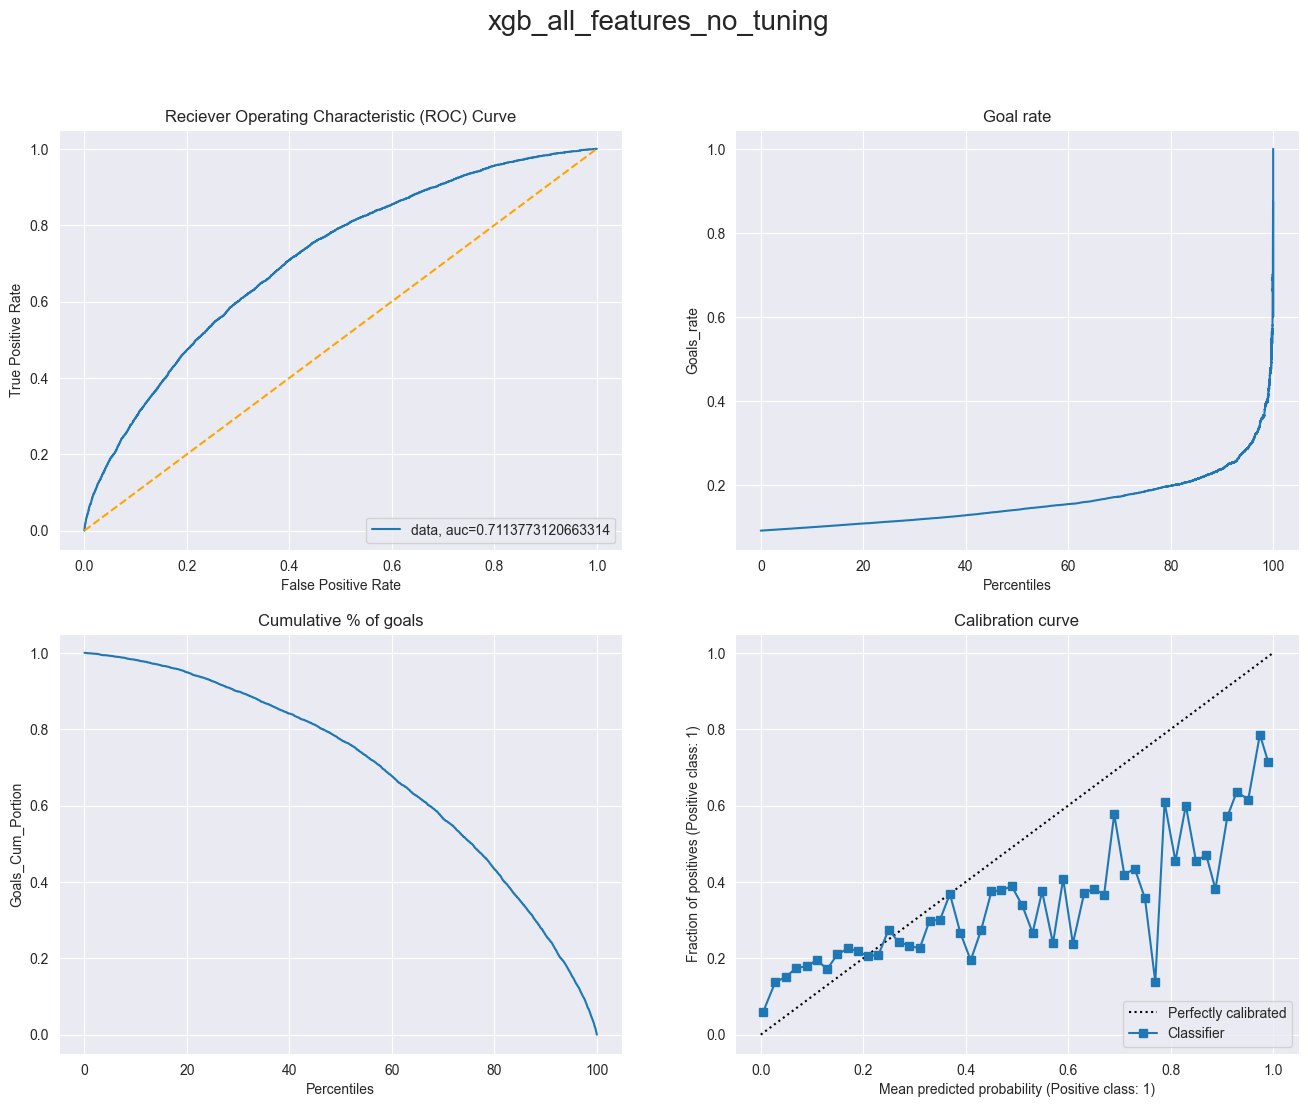

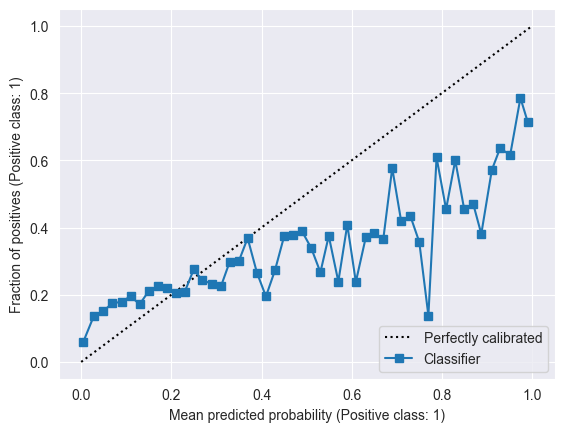

In [83]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, model.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, model.predict(X_test))
print(f"f1 score: {f1}")

In [84]:
model = xgb.XGBClassifier(tree_method = 'gpu_hist', max_depth = 0, max_delta_step = 0, gamma = 0, scale_pos_weight = 1)
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0, gpu_id=0,
              grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=0, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0, ...)

f1 score: 0.08988037504041384


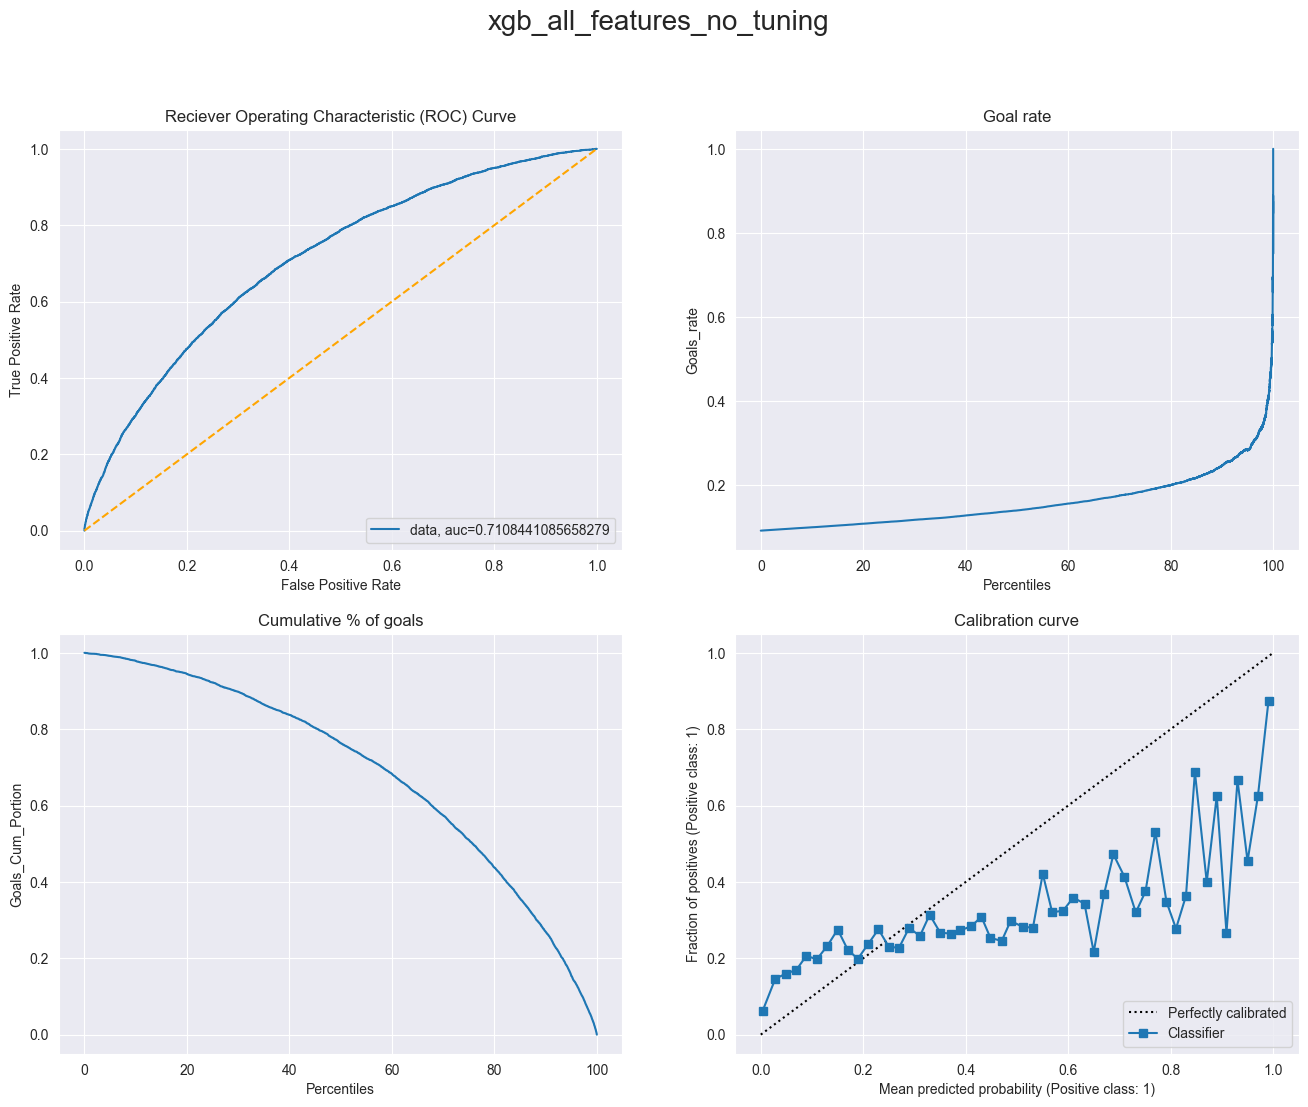

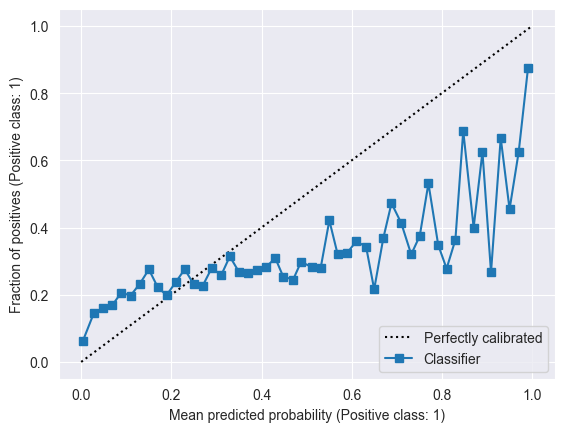

In [85]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, model.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, model.predict(X_test))
print(f"f1 score: {f1}")

In [87]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),
     'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='roc_auc', cv=5,  #plus iterations, plus chances trouver la bonne combinaison
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [88]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'scale_pos_weight': 1.0, 'max_depth': 5, 'max_delta_step': 3.0, 'gamma': 1.2653061224489794}
0.7579348952768107


f1 score: 0.08988037504041384


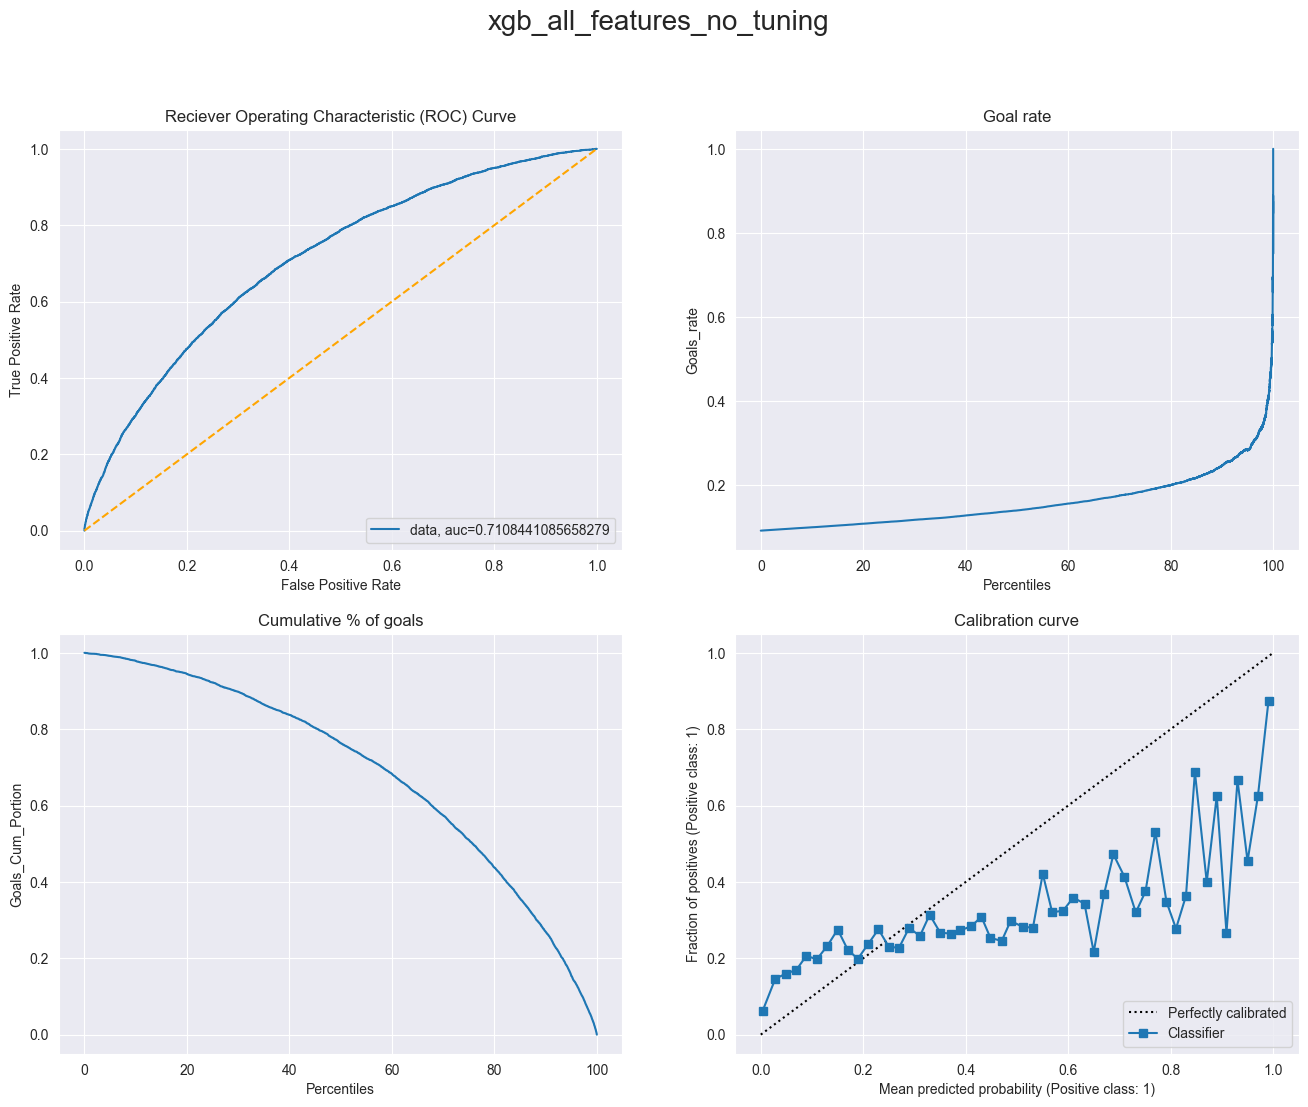

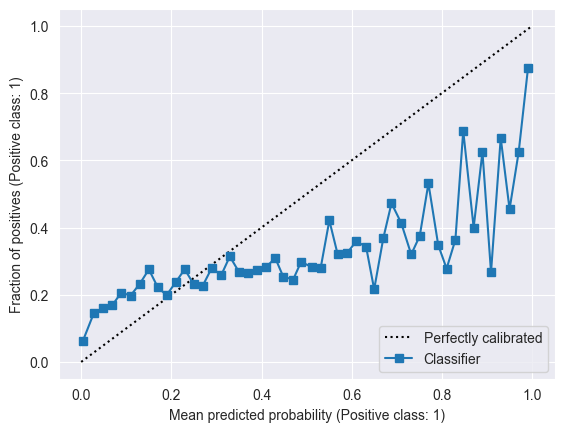

In [89]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, model.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, model.predict(X_test))
print(f"f1 score: {f1}")

In [91]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),
     'scale_pos_weight': [0.1, 1.0],
    'eta': np.linspace(0,0.6, num=50)
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='roc_auc', cv=5,  #plus iterations, plus chances trouver la bonne combinaison
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [92]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'scale_pos_weight': 1.0, 'max_depth': 6, 'max_delta_step': 8.0, 'gamma': 0.0, 'eta': 0.12244897959183673}
0.7592621683335637


f1 score: 0.08988037504041384


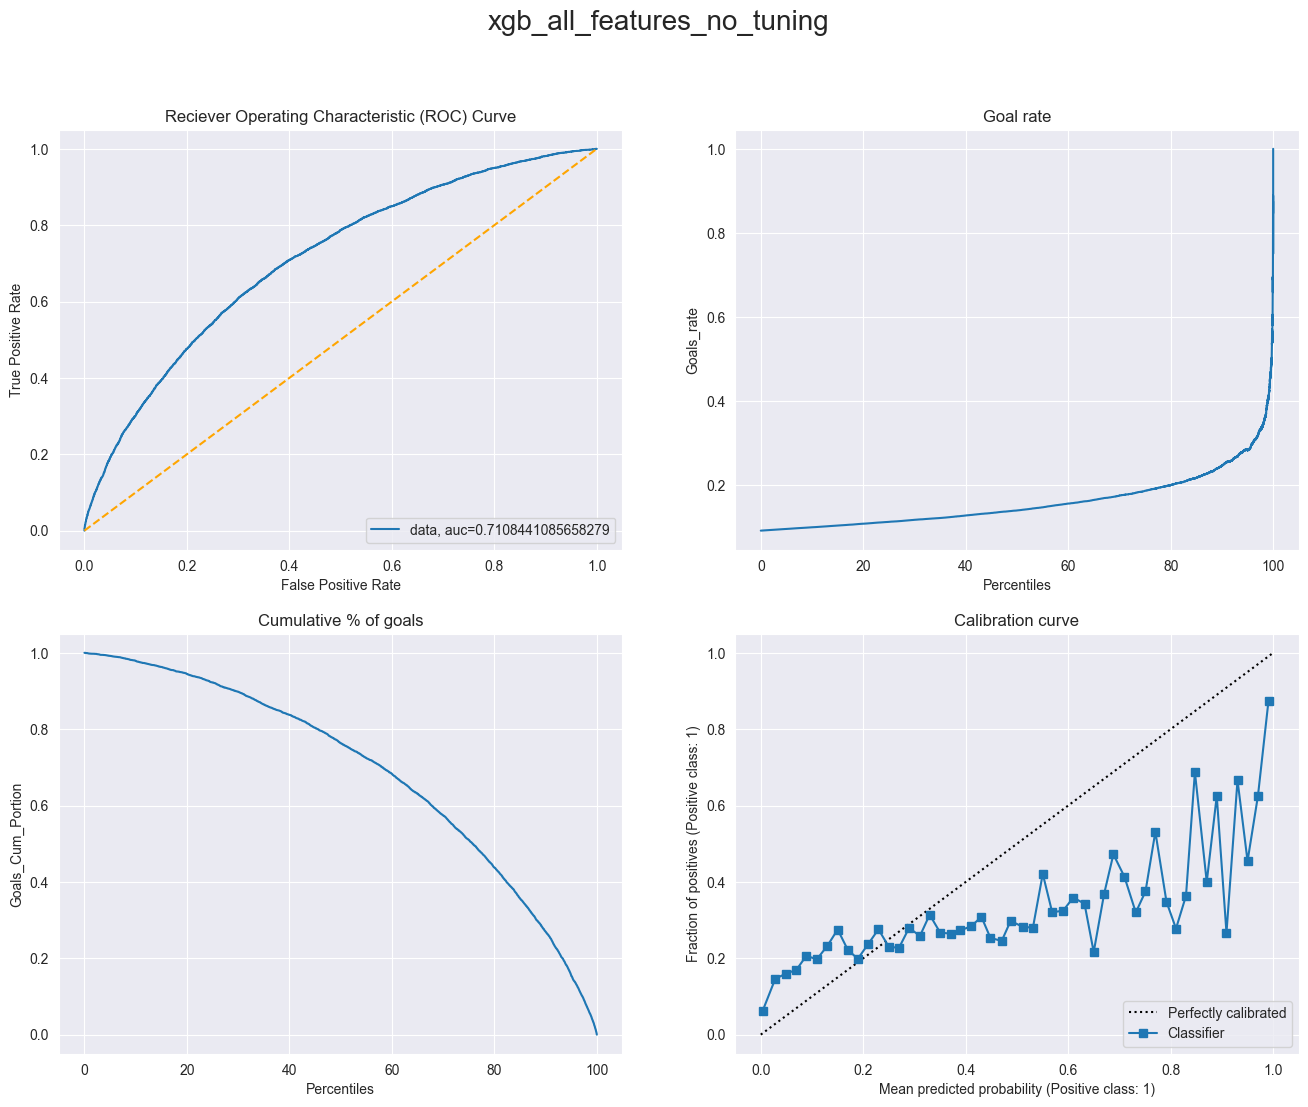

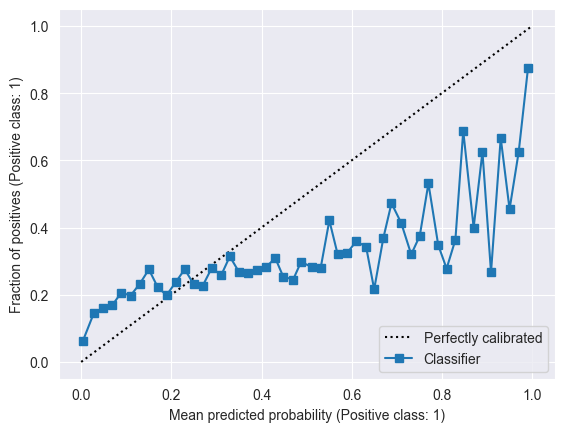

In [93]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, model.predict_proba(X_test)[:,1], 50)
f1 = metrics.f1_score(y_test, model.predict(X_test))
print(f"f1 score: {f1}")

## FEATURE SELECTION

In [99]:
df.corr().iloc[:,0:9].style.background_gradient(cmap='Blues')

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\2641464027.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr().iloc[:,0:9].style.background_gradient(cmap='Blues')


,Period_Time_Seconds,Period,X_Coordinate,Y_Coordinate,Distance_Net,Angle,Last_Coordinate_X,Last_Coordinate_Y,Time_Between_Events
Period_Time_Seconds,1.000000,-0.046654,-0.004644,-0.000923,0.007301,-0.001094,-0.003250,-0.003241,0.021502
Period,-0.046654,1.000000,0.000981,0.001343,-0.005571,-0.001425,0.004282,0.000488,0.051645
X_Coordinate,-0.004644,0.000981,1.000000,-0.008387,-0.005625,-0.030282,0.378855,-0.003693,-0.002531
Y_Coordinate,-0.000923,0.001343,-0.008387,1.000000,0.003401,0.830901,-0.004530,0.045930,-0.009678
Distance_Net,0.007301,-0.005571,-0.005625,0.003401,1.000000,0.009876,-0.005964,0.002199,0.037302
Angle,-0.001094,-0.001425,-0.030282,0.830901,0.009876,1.000000,-0.010404,0.046840,-0.004900
Last_Coordinate_X,-0.003250,0.004282,0.378855,-0.004530,-0.005964,-0.010404,1.000000,-0.011573,-0.000818
Last_Coordinate_Y,-0.003241,0.000488,-0.003693,0.045930,0.002199,0.046840,-0.011573,1.000000,0.003816
Time_Between_Events,0.021502,0.051645,-0.002531,-0.009678,0.037302,-0.004900,-0.000818,0.003816,1.000000
Distance_Last_Event,-0.022785,0.005767,-0.001263,-0.005558,0.000698,-0.003244,0.003200,0.005486,0.175675


In [105]:
df.corr().iloc[:,9:17].style.background_gradient(cmap='Blues')

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\380200543.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr().iloc[:,9:17].style.background_gradient(cmap='Blues')


,Distance_Last_Event,Rebond,Delta_Angle,Speed,Powerplay_Since,Friendly_Non_Goalies,Opponent_Non_Goalies,is_goal
Period_Time_Seconds,-0.022785,-0.001199,-0.000933,-0.017468,0.064191,-0.050483,-0.070739,0.023842
Period,0.005767,0.014270,0.000301,-0.036807,-0.018078,0.020692,0.025144,0.032967
X_Coordinate,-0.001263,0.003003,-0.021178,0.001549,-0.001922,0.001048,0.001033,-0.001286
Y_Coordinate,-0.005558,0.005687,0.780913,0.008777,0.010459,-0.004917,-0.013395,0.006184
Distance_Net,0.000698,-0.087877,0.007439,-0.028340,-0.002886,-0.069562,0.042355,-0.111123
Angle,-0.003244,0.001290,0.928821,0.005741,0.008073,-0.003849,-0.012384,0.004999
Last_Coordinate_X,0.003200,0.000607,-0.001423,0.002406,-0.000853,0.000778,-0.000240,-0.001402
Last_Coordinate_Y,0.005486,-0.004896,-0.054995,0.000601,0.006019,-0.003146,-0.006689,0.003442
Time_Between_Events,0.175675,-0.067141,-0.006439,-0.417052,0.082103,0.005352,-0.054388,-0.045707
Distance_Last_Event,1.000000,-0.101173,-0.006293,0.308100,-0.114093,-0.053278,0.184224,-0.024297


In [106]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
my_selector = SelectKBest(mutual_info_classif, k=8)
my_selector.fit(X_train,y_train)
features_out = my_selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]

In [107]:
transformed_features[features_out_indices]

array(['standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Wrist Shot', 'remainder__Period',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

In [108]:
my_selector.scores_

array([0.00133783, 0.01302507, 0.01693549, 0.01992288, 0.01391235,
       0.00225974, 0.00314735, 0.00645916, 0.00340685, 0.00841189,
       0.00690258, 0.01303995, 0.00058624, 0.00041031, 0.00211402,
       0.00058575, 0.00327032, 0.        , 0.0140558 , 0.00100356,
       0.0032308 , 0.00037995, 0.00096207, 0.0025529 , 0.00054482,
       0.        , 0.0021339 , 0.        , 0.01343866, 0.00235466,
       0.04781545, 0.04095941])

In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
my_log_reg = LogisticRegression(penalty='l1', solver="liblinear")
selector = SelectFromModel(my_log_reg, max_features=8).fit(X_train,y_train)
features_out = selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]
transformed_features[features_out_indices]

array(['standard__Distance_Net', 'one-hot__Shoot_Type_Backhand',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Faceoff', 'one-hot__Last_Event_Type_Hit'],
      dtype=object)

In [114]:
from sklearn.feature_selection import  SequentialFeatureSelector
feature_selector = SequentialFeatureSelector(xgb.XGBClassifier(tree_method= 'gpu_hist'), n_features_to_select=8, direction="forward", scoring="f1")

In [115]:
%%time
feature_selector.fit(X_train,y_train)

CPU times: total: 1h 8min 11s
Wall time: 7min 42s


SequentialFeatureSelector(estimator=XGBClassifier(base_score=None, booster=None,
                                                  callbacks=None,
                                                  colsample_bylevel=None,
                                                  colsample_bynode=None,
                                                  colsample_bytree=None,
                                                  early_stopping_rounds=None,
                                                  enable_categorical=False,
                                                  eval_metric=None,
                                                  feature_types=None,
                                                  gamma=None, gpu_id=None,
                                                  grow_policy=None,
                                                  importance_type=None,
                                                  interaction_constraints=None,
                                                  learning_rate=None,
                                                  max_bin=None,
                                                  max_cat_threshold=None,
                                                  max_cat_to_onehot=None,
                                                  max_delta_step=None,
                                                  max_depth=None,
                                                  max_leaves=None,
                                                  min_child_weight=None,
                                                  missing=nan,
                                                  monotone_constraints=None,
                                                  n_estimators=100, n_jobs=None,
                                                  num_parallel_tree=None,
                                                  predictor=None,
                                                  random_state=None, ...),
                          n_features_to_select=8, scoring='f1')

In [116]:
features_out = feature_selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]
transformed_features[features_out_indices]

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Distance_Net', 'standard__Distance_Last_Event',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Tip-In', 'remainder__Period'], dtype=object)